# ECCC GeoMet daily climate observations

Inspect daily observations from ECCC GeoMet at Toronto International Airport (climate ID `6158731`) for 2020. The GeoMet climate ID identifies a station record; the separate `STN_ID` field is a web station identifier. GeoMet publishes a selected subset of stations rather than the entire archive. Daily dates are source local-date labels, not an asserted uniform UTC observation window.

The [companion pipeline](../../pipelines/eccc_daily_pipeline.py) caches the source's features with per-page and snapshot checksums and streams typed rows to Parquet. Nulls and ECCC quality flags are retained without interpreting them as accepted or rejected measurements. For example, `T` marks trace precipitation; treating its numerical zero as an ordinary measured zero would lose that distinction. This is a station-point record, not area interpolation, an AHCCD homogenized series, or a subdaily rainfall-intensity curve.

Data source: Environment and Climate Change Canada. The [daily observation dataset](https://open.canada.ca/data/en/dataset/5f963c2d-d4ed-5a79-8a31-c9c582ca5098) is under the Open Government Licence – Canada; see the [ECCC data services licence](https://eccc-msc.github.io/open-data/licence/readme_en/) and [source documentation](https://eccc-msc.github.io/open-data/msc-data/climate_obs/readme_climateobs_en/). The separate Historical Climate Data website links to its own redistribution conditions; this example uses GeoMet.

Run from a local crc-docs checkout: use `uv sync`, then launch Jupyter with
`uv run jupyter lab` and select the project kernel. The first pipeline run
requires internet access.


In [1]:
# Check the local notebook environment before running the pipeline.
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "plotly>=6", "crc-sdk>=0.11.1,<1"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))

import os

import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
from pipelines.eccc_daily_pipeline import run
import pyarrow.parquet as pq

output = root / "pipeline_output" / "eccc_daily"
summary = run(output)
print("Observations:", summary["observations"])
for source in summary["sources"]:
    print(source["year"], "snapshot:", source["sha256"], "retrieved:", source["retrieved_at"])

Observations: 366
2020 snapshot: cbff776bebd8297fb960be06464f255da978cc33b7f4a348afdee4ec21094c1d retrieved: 2026-10-30T19:22:25.474995+00:00


In [2]:
# Small example only: the pipeline writes batches rather than loading the whole series.
daily = pq.read_table(output / "daily.parquet").to_pandas()
print("Climate IDs:", daily["CLIMATE_IDENTIFIER"].dropna().unique())
print("Web station IDs:", daily["STN_ID"].dropna().unique())
print("Unique dates:", daily["date"].nunique(), "of 366")
print("Precipitation flags:", daily["TOTAL_PRECIPITATION_FLAG"].value_counts(dropna=False).to_dict())
daily.sort_values("date")[["date", "MAX_TEMPERATURE", "MAX_TEMPERATURE_FLAG", "TOTAL_PRECIPITATION", "TOTAL_PRECIPITATION_FLAG"]].head()

Climate IDs: <ArrowStringArray>
['6158731']
Length: 1, dtype: str
Web station IDs: [51459]
Unique dates: 366 of 366
Precipitation flags: {nan: 323, 'T': 43}


,date,MAX_TEMPERATURE,MAX_TEMPERATURE_FLAG,TOTAL_PRECIPITATION,TOTAL_PRECIPITATION_FLAG
0,2020-01-01,-0.2,NaN,0.0,T
1,2020-01-02,6.4,NaN,0.0,NaN
2,2020-01-03,6.8,NaN,0.0,NaN
3,2020-01-04,2.5,NaN,1.6,NaN
4,2020-01-05,1.3,NaN,3.6,NaN


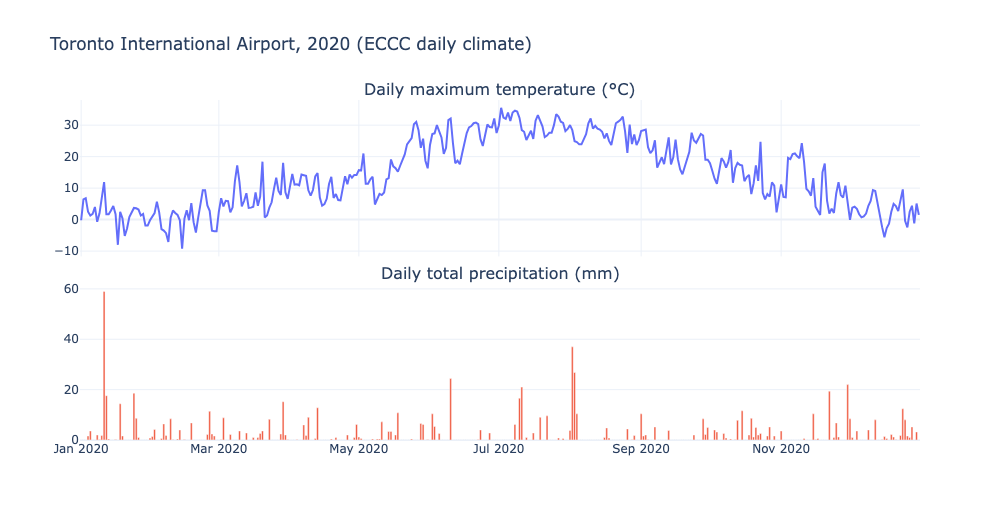

In [3]:
# Daily maximum temperature and precipitation; missing values stay gaps.
view = daily.sort_values("date")
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=("Daily maximum temperature (°C)", "Daily total precipitation (mm)"))
fig.add_trace(go.Scatter(x=view["date"], y=view["MAX_TEMPERATURE"], mode="lines",
                         name="Max temperature", connectgaps=False), row=1, col=1)
fig.add_trace(go.Bar(x=view["date"], y=view["TOTAL_PRECIPITATION"], name="Precipitation"), row=2, col=1)
fig.update_layout(title="Toronto International Airport, 2020 (ECCC daily climate)", showlegend=False, height=520)
fig.show()


Before fitting extremes or aggregating rainfall, choose and document a quality policy, completeness requirements and an appropriate observation window. The example deliberately applies none. Source records and availability can change; a multi-page acquisition is not a transactional upstream snapshot. Retain the cache and manifest to reproduce the captured records.